In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the notebook folder whether the kernel starts in the repo root or notebooks/.
notebook_dir = next(
    (p / "notebooks" if (p / "notebooks" / "resolution.ipynb").is_file() else p)
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "notebooks" / "resolution.ipynb").is_file()
    or (p / "resolution.ipynb").is_file()
)
CSV_PATH = notebook_dir / "data/supabase_exports/20261028T050019Z_hxekxttx/resolutions.csv"
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"Resolutions CSV not found: {CSV_PATH}")

# PostgreSQL exports use \N for missing values and t/f for booleans.
df = pd.read_csv(CSV_PATH, na_values=[r"\N"], true_values=["t"], false_values=["f"])
df = df.loc[df["uma_resolution_status"].eq("resolved")].copy()
if df.empty:
    raise ValueError("The CSV contains no finalized resolutions.")

# Parse once so both time-based plots use the same Pacific-time timestamps.
# Invalid nonmissing timestamps raise an error rather than silently dropping rows.
df["resolved_at"] = pd.to_datetime(
    df["resolved_at"], format="mixed", utc=True, errors="raise"
).dt.tz_convert("America/Los_Angeles")
resolved = df["resolved_at"].dropna()
if resolved.empty:
    raise ValueError("No finalized resolutions have timestamps for the time-based plots.")


Month
Jan 2026         1
Feb 2026         0
Mar 2026         0
Apr 2026         0
May 2026      3238
Jun 2026     33851
Jul 2026      6380
Aug 2026     14684
Sep 2026    128044
Oct 2026    141558


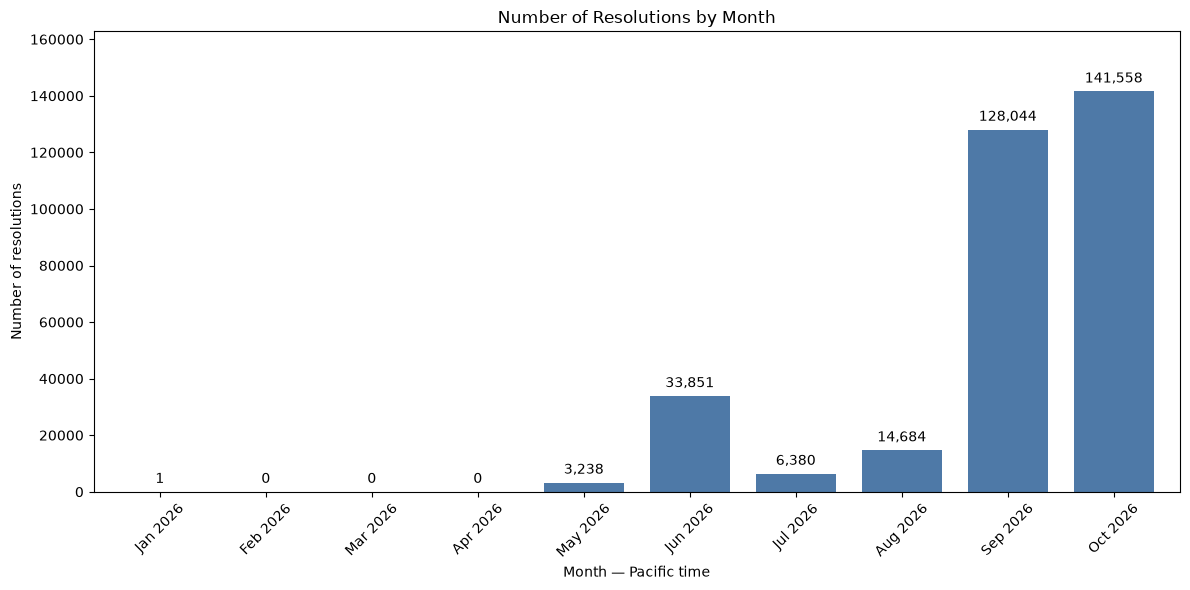

In [2]:
# Count resolutions by month, including months with zero resolutions.
monthly_counts = (
    df.dropna(subset=["resolved_at"]).set_index("resolved_at")
    .resample("MS")
    .size()
    .rename("Resolutions")
)

monthly_counts.index = monthly_counts.index.strftime("%b %Y")
monthly_counts.index.name = "Month"

print(monthly_counts.to_string())

# Plot monthly counts.
ax = monthly_counts.plot(
    kind="bar",
    figsize=(12, 6),
    color="#4E79A7",
    width=0.75,
)

ax.bar_label(
    ax.containers[0],
    labels=[f"{count:,}" for count in monthly_counts],
    padding=4,
)

ax.set_title("Number of Resolutions by Month")
ax.set_xlabel("Month — Pacific time")
ax.set_ylabel("Number of resolutions")
ax.tick_params(axis="x", rotation=45)
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

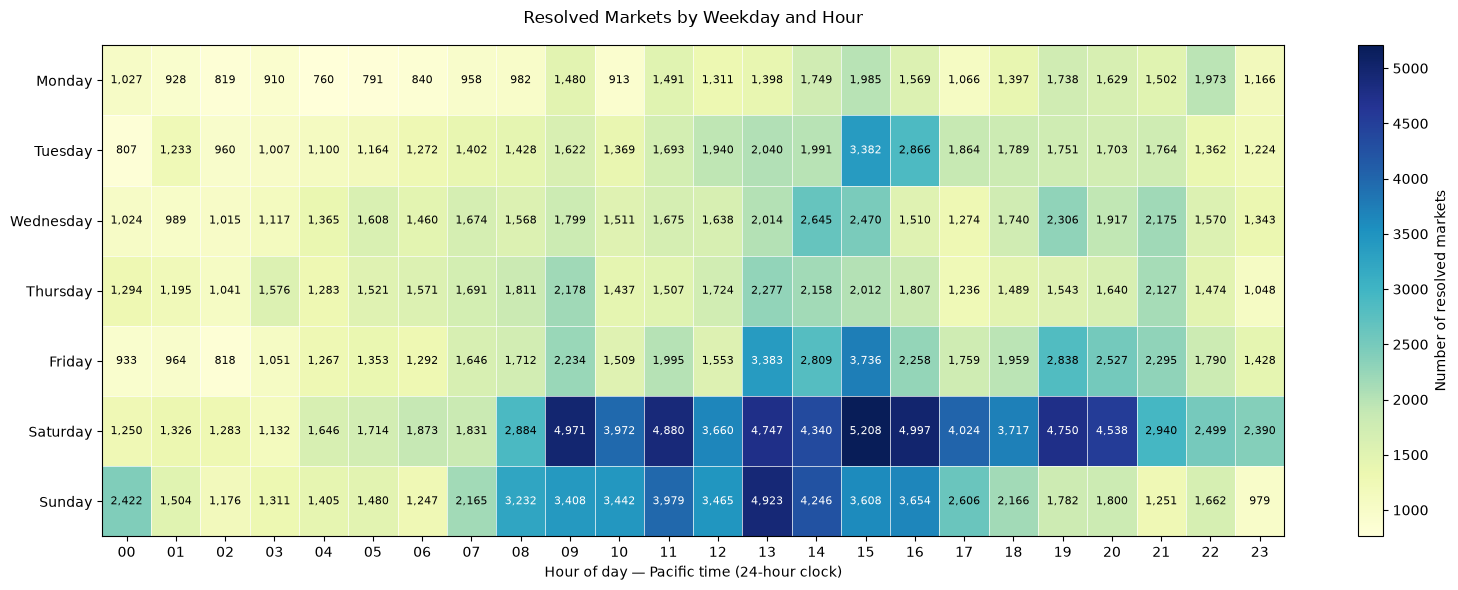

In [3]:
weekdays = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

activity = pd.crosstab(
    resolved.dt.day_name(),
    resolved.dt.hour,
).reindex(index=weekdays, columns=range(24), fill_value=0)

# Matplotlib keeps this plot usable without an additional Seaborn dependency.
fig, ax = plt.subplots(figsize=(16, 6))
image = ax.imshow(activity.to_numpy(), cmap="YlGnBu", aspect="auto")
fig.colorbar(image, ax=ax, label="Number of resolved markets")
for row in range(len(weekdays)):
    for hour in range(24):
        count = int(activity.iloc[row, hour])
        ax.text(
            hour, row, f"{count:,}", ha="center", va="center", fontsize=8,
            color="white" if image.norm(count) > 0.5 else "black",
        )

ax.set_title("Resolved Markets by Weekday and Hour", pad=16)
ax.set_xlabel("Hour of day — Pacific time (24-hour clock)")
ax.set_ylabel("")
ax.set_xticks(range(24), labels=[f"{hour:02d}" for hour in range(24)])
ax.set_yticks(range(len(weekdays)), labels=weekdays)
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(weekdays), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()


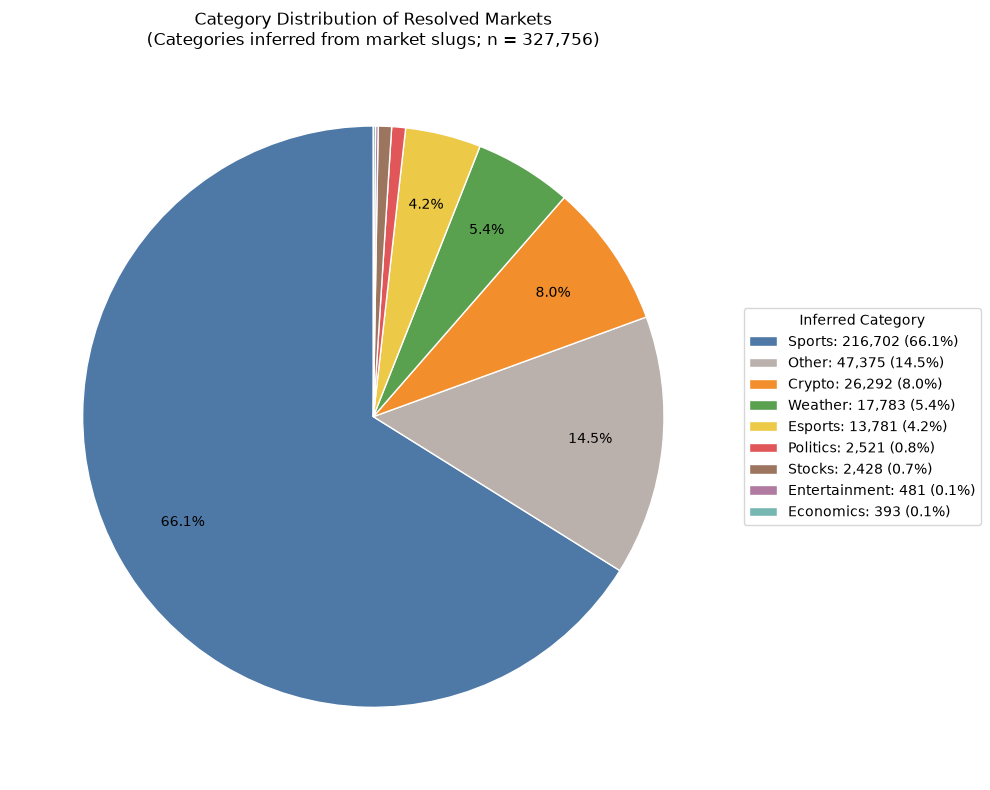

               Markets  Percentage
category                          
Sports          216702       66.12
Other            47375       14.45
Crypto           26292        8.02
Weather          17783        5.43
Esports          13781        4.20
Politics          2521        0.77
Stocks            2428        0.74
Entertainment      481        0.15
Economics          393        0.12

Examples remaining in Other:
                     mlbb-yndx-ts-2026-10-04-game1
       mlbb-re1-rakuza-2026-10-04-total-games-2pt5
mlbb-re1-rakuza-2026-10-04-game-handicap-home-1pt5
                     mlbb-yndx-ts-2026-10-04-game2
mlbb-re1-rakuza-2026-10-04-game-handicap-away-1pt5
                        mlbb-re1-rakuza-2026-10-04
          mlbb-bur-slx-2026-10-04-total-games-2pt5
                      mlbb-aurevi-lvlup-2026-10-04
     mlbb-aurevi-lvlup-2026-10-04-total-games-2pt5
mlbb-aurevi-lvlup-2026-10-04-game-handicap-away...
                  mlbb-re1-rakuza-2026-10-04-game1
 mlbb-onic-navi-2026-10-

In [4]:
slugs = df["market_slug"].fillna("").str.lower()

# Categories are inferred from slug keywords and competition prefixes.
sports_prefixes = [
    "nba", "wnba", "nfl", "mlb", "nhl", "ncaa", "epl", "ufc",
    "atp", "wta", "itf", "cfb", "mls", "nwsl", "ucl", "uel",
    "fifwc", "fif", "unl", "efa", "efl",
    "lal", "el1", "el2", "es2", "fl1",
    "mex", "sea", "bra", "bra2", "conl",
    "ja2", "jap", "enl", "tur", "gtm",
    "arg", "argpn", "elc", "scoc", "scop",
    "spl", "bun", "bl2", "por", "ere",
    "uslc", "ptc", "itsb", "fpd", "col1",
    "col2", "col", "bol1", "chi", "cdr",
    "nor", "kor", "ukr1", "ned2", "fr2",
    "per1", "uru1", "ecu1", "uzb1", "chl2",
    "egy1", "rou1", "qat1", "bel1", "slo",
    "ahl", "mlp", "dpwt", "f1", "nascar",
]

sports_pattern = (
    r"^(?:" + "|".join(sports_prefixes) + r")-"
    r"|^setka[a-z]*-"
    r"|^cri[a-z]*-"
    r"|\b(?:tennis|soccer|football|basketball|baseball|hockey|"
    r"uefa|champions-league|us-open|pga)\b"
)

# First matching category wins.
patterns = {
    "Weather": (
        r"^(?:highest|lowest)-temperature-"
        r"|\b(?:rainfall|snowfall|precipitation|hurricane)\b"
    ),
    "Esports": r"^(?:cs2|lol|dota2|val|hok|ow)-",
    "Sports": sports_pattern,
    "Crypto": (
        r"\b(?:bitcoin|btc|ethereum|eth|solana|sol|crypto|"
        r"dogecoin|doge|xrp|bnb|hype|zec|ada|avax|sui|link)\b"
    ),
    "Stocks": (
        r"\b(?:nflx|aapl|msft|nvda|tsla|amzn|googl|goog|meta|"
        r"stock|stocks|share-price|market-cap)\b"
    ),
    "Politics": (
        r"\b(?:trump|biden|harris|election|president|presidential|"
        r"senate|congress|governor|democrat|democratic|republican)\b"
    ),
    "Economics": (
        r"\b(?:fed|fomc|inflation|cpi|gdp|recession|unemployment|"
        r"interest-rates?|nasdaq|sp500|s-p-500)\b"
    ),
    "Entertainment": (
        r"\b(?:oscars?|grammys?|emmys?|box-office|billboard|spotify)\b"
    ),
}

df["category"] = np.select(
    [
        slugs.str.contains(pattern, regex=True, na=False).to_numpy()
        for pattern in patterns.values()
    ],
    list(patterns),
    default="Other",
)

counts = df["category"].value_counts()

colors = {
    "Sports": "#4E79A7",
    "Crypto": "#F28E2B",
    "Politics": "#E15759",
    "Economics": "#76B7B2",
    "Entertainment": "#B07AA1",
    "Weather": "#59A14F",
    "Esports": "#EDC948",
    "Stocks": "#9C755F",
    "Other": "#BAB0AC",
}

fig, ax = plt.subplots(figsize=(12, 8))

wedges, _, _ = ax.pie(
    counts,
    colors=[colors[category] for category in counts.index],
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 2 else "",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)

ax.legend(
    wedges,
    [
        f"{category}: {count:,} ({count / counts.sum():.1%})"
        for category, count in counts.items()
    ],
    title="Inferred Category",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

ax.set_title(
    f"Category Distribution of Resolved Markets\n"
    f"(Categories inferred from market slugs; n = {counts.sum():,})"
)

plt.tight_layout()
plt.show()

# Print counts and percentages.
summary = pd.DataFrame({
    "Markets": counts,
    "Percentage": (100 * counts / counts.sum()).round(2),
})
print(summary.to_string())

# Review markets the rules did not classify.
print("\nExamples remaining in Other:")
print(
    df.loc[df["category"].eq("Other"), "market_slug"]
    .head(30)
    .to_string(index=False))
